In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

data = pd.read_csv("student.csv")

x = data[['Hours']]  #double bracketts = 2D input
y = data['Score']  #target column

model = LinearRegression()
model.fit(x,y)

predicted_score = model.predict(x)

#evaluate
mae = mean_absolute_error(y, predicted_score)
mse = mean_squared_error(y, predicted_score)
rmse = np.sqrt(mse)

#show results
print("Mean Absolute Error(MAE):", mae)
print("Mean Squared Error(MSE):", mse)
print("Root Mean Squared Error(RMSE):", rmse)

new_hour = float(input("enter a hour = "))
new_pred = model.predict([[new_hour]])
print(f"Prediction for {new_hour} is score ={new_pred}")

Mean Absolute Error(MAE): 0.6666666666666643
Mean Squared Error(MSE): 0.6285714285714282
Root Mean Squared Error(RMSE): 0.7928249671720916
Prediction for 5.0 is score =[75.02857143]


C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Mean Absolute Error(MAE): 7.17
Mean Squared Error(MSE): 81.04
Root Mean Squared Error(RMSE): 9.0
R^2 score (Model Accuracy): 0.6597


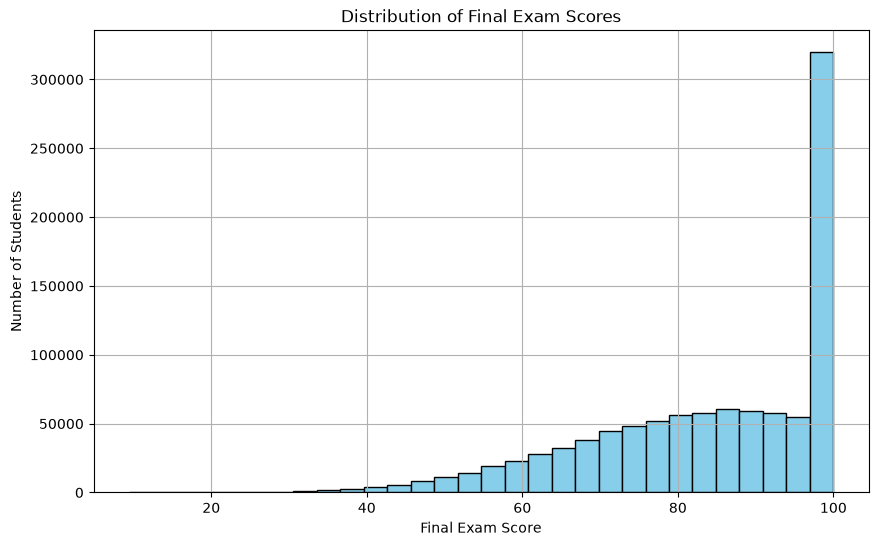

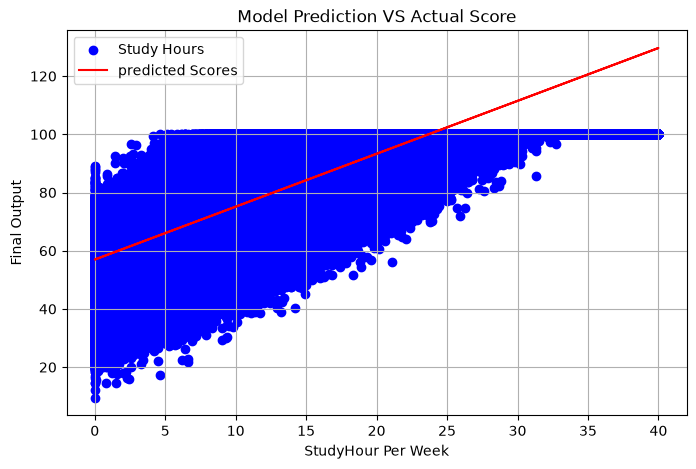

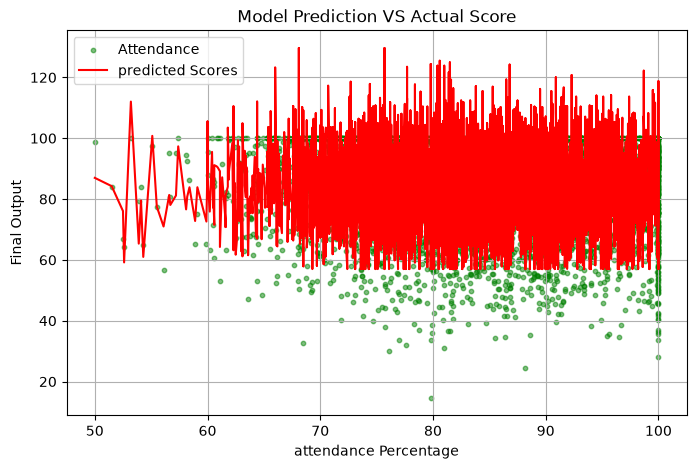

predicted Final Score for 2 StudyHours and 50% attendance is  60.62 Score


C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [21]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
import matplotlib.pyplot as plt
import numpy as np

#load dataset
data = pd.read_csv("student_performance.csv")

#Input & Output
x = data[['weekly_self_study_hours','attendance_percentage']]
y = data['total_score']

#train model
model = LinearRegression()
model.fit(x,y)
predicted_scores = model.predict(x)

#valid regression metrics
mae = mean_absolute_error(y, predicted_scores)
mse = mean_squared_error(y, predicted_scores)
rmse = np.sqrt(mse)
r2 = r2_score(y, predicted_scores)

#show results
"""
3.12345
round(3.12345,2)
3.12
"""

print("Mean Absolute Error(MAE):", round(mae,2))
print("Mean Squared Error(MSE):", round(mse,2))
print("Root Mean Squared Error(RMSE):", round(rmse,2))
print("R^2 score (Model Accuracy):", round(r2,4)) #closer to 1 = better

#Histogram
plt.figure(figsize=(10,6))
plt.hist(data["total_score"],bins=30, color='skyblue',edgecolor='black')
plt.title("Distribution of Final Exam Scores")
plt.xlabel("Final Exam Score")
plt.ylabel("Number of Students")
plt.grid(True)
plt.show()

#Scatter + Regression Line
plt.figure(figsize=(8,5))
plt.scatter(x['weekly_self_study_hours'], y, color='blue',label='Study Hours')
plt.plot(x['weekly_self_study_hours'], predicted_scores, color='red', label='predicted Scores')
plt.title("Model Prediction VS Actual Score")
plt.xlabel("StudyHour Per Week")
plt.ylabel("Final Output")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(x['attendance_percentage'].iloc[:5000], y.iloc[:5000], color='green',label='Attendance',s=10,alpha=0.5,rasterized=True)
plt.plot(x['attendance_percentage'].iloc[:5000].sort_values().values, predicted_scores[x['attendance_percentage'].iloc[:5000].sort_values().index], color='red', label='predicted Scores',rasterized=True)
plt.title("Model Prediction VS Actual Score")
plt.xlabel("attendance Percentage")
plt.ylabel("Final Output")
plt.grid(True)
plt.legend()
plt.show()

new_hours = 2
new_attendance = 50
predicted_new_score = model.predict([[new_hours, new_attendance]])[0]
print(f"predicted Final Score for {new_hours} StudyHours "
     f"and {new_attendance}% attendance is {predicted_new_score : .2f} Score")